# Recipe & Ingredient Explorer: demo

What the project does, with the real graph and the real API.

Before running: make docker-run, make seed, make gds (and a Gemini key in .env for part 8).
The API is called through Nginx on http://localhost:8080, the graph is read directly from Neo4j.

In [1]:
import httpx
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from app.config import settings
from app.database.neo4j_client import Neo4jClient

API = "http://localhost:8080"
db = Neo4jClient(settings.neo4j_uri, settings.neo4j_user, settings.neo4j_password)
COLORS = {"Recipe": "#f4a261", "Ingredient": "#2a9d8f", "Cuisine": "#9b5de5", "Diet": "#e76f51", "Course": "#457b9d"}


def api(path, **params):
    return httpx.get(API + path, params=params, timeout=60).json()


def draw(edges, title, size=(11, 7)):
    # edges: list of (start, start label, end, end label, relationship type)
    graph = nx.Graph()
    for start, start_label, end, end_label, rel in edges:
        graph.add_node(start, label=start_label)
        graph.add_node(end, label=end_label)
        graph.add_edge(start, end, rel=rel)
    pos = nx.spring_layout(graph, seed=7, k=0.9)
    plt.figure(figsize=size)
    nx.draw_networkx_nodes(graph, pos, node_size=900,
                           node_color=[COLORS.get(graph.nodes[n]["label"], "#ccc") for n in graph])
    nx.draw_networkx_edges(graph, pos, alpha=0.4)
    nx.draw_networkx_labels(graph, pos, labels={n: n[:22] for n in graph}, font_size=8)
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=nx.get_edge_attributes(graph, "rel"), font_size=6)
    for label, color in COLORS.items():
        plt.scatter([], [], color=color, label=label)
    plt.legend(loc="lower left")
    plt.title(title)
    plt.axis("off")
    plt.show()


api("/health")

{'status': 'ok', 'neo4j': 'up'}

## 1. What is in the graph

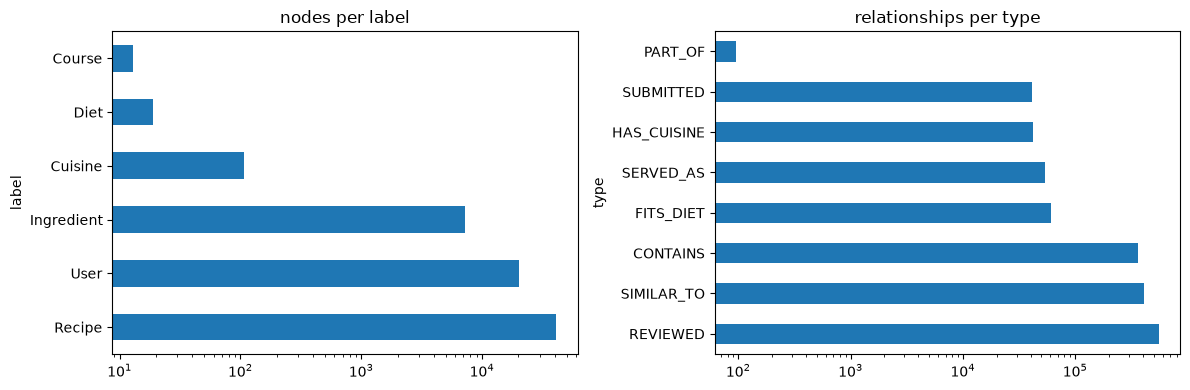

,label,nodes,type,relationships
0,Recipe,41240.0,REVIEWED,555618
1,User,20187.0,SIMILAR_TO,407455
2,Ingredient,7157.0,CONTAINS,363928
3,Cuisine,106.0,FITS_DIET,61179
4,Diet,19.0,SERVED_AS,53724
5,Course,13.0,HAS_CUISINE,41791
6,NaN,NaN,SUBMITTED,41240
7,NaN,NaN,PART_OF,95


In [2]:
labels = pd.DataFrame(db.run_read("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS nodes ORDER BY nodes DESC"))
rels = pd.DataFrame(db.run_read("MATCH ()-[r]->() RETURN type(r) AS type, count(*) AS relationships ORDER BY relationships DESC"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels.plot.barh(x="label", y="nodes", ax=axes[0], legend=False, title="nodes per label", logx=True)
rels.plot.barh(x="type", y="relationships", ax=axes[1], legend=False, title="relationships per type", logx=True)
plt.tight_layout()
plt.show()
labels.merge(rels, how="outer", left_index=True, right_index=True)

Takeaways:
- 7 labels and 9 relationship types (log scale: REVIEWED and SIMILAR_TO are the big ones)
- SIMILAR_TO is not from the data, it was computed by GDS (part 4)

## 2. One recipe and its neighbourhood

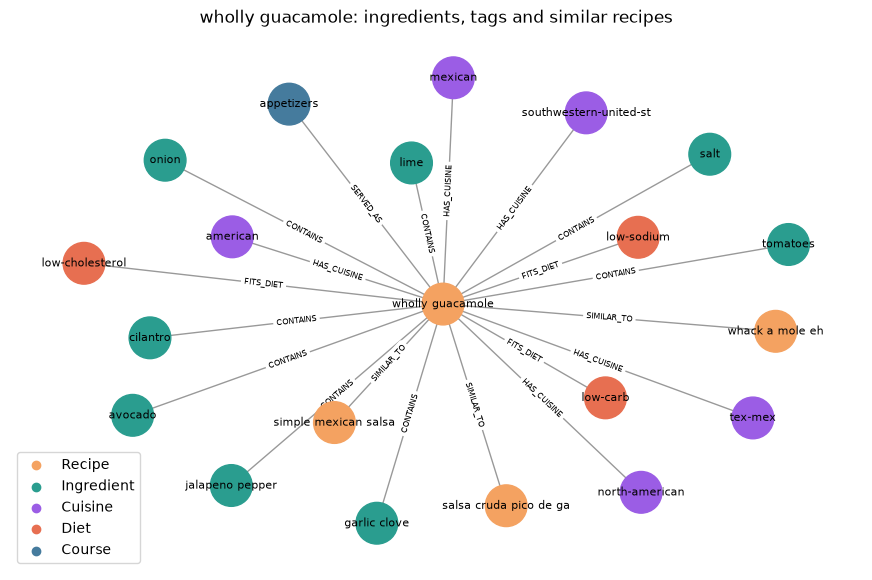

In [3]:
RECIPE_ID = 8739  # wholly guacamole
rows = db.run_read('''
MATCH (r:Recipe {id: $id})
CALL (r) {
  MATCH (r)-[rel:CONTAINS|HAS_CUISINE|FITS_DIET|SERVED_AS]->(x)
  RETURN r.name AS start, 'Recipe' AS start_label, x.name AS end, labels(x)[0] AS end_label, type(rel) AS rel
  UNION
  MATCH (r)-[s:SIMILAR_TO]->(o:Recipe) WITH r, o ORDER BY s.score DESC LIMIT 3
  RETURN r.name AS start, 'Recipe' AS start_label, o.name AS end, 'Recipe' AS end_label, 'SIMILAR_TO' AS rel
}
RETURN start, start_label, end, end_label, rel
''', {"id": RECIPE_ID})
draw([tuple(row.values()) for row in rows], "wholly guacamole: ingredients, tags and similar recipes")

Takeaways:
- ingredients, cuisine, diet and course are separate nodes, so other recipes connect to the same nodes
- the 3 orange neighbours are its most similar recipes (SIMILAR_TO)

## 3. Search by ingredients (API)

In [4]:
result = api("/api/recipes/search", ingredients="eggs, parmesan", course="main dish", cuisine="italian", max_minutes=30, limit=5)
print(result["ingredients"])
pd.DataFrame(result["results"])[["name", "minutes", "reviews", "missing_ingredients"]]

[{'typed': 'eggs', 'name': 'egg', 'method': 'singular'}, {'typed': 'parmesan', 'name': 'parmesan cheese', 'method': 'closest'}]


,name,minutes,reviews,missing_ingredients
0,frittata di spaghetti spaghetti omelet,17,9,"[salt, butter, spaghetti, ground black pepper]"
1,cheese filling for ravioli,5,6,"[parsley, nutmeg, pasta dough, salt, ricotta c..."
2,boneless pork chops milanese,26,14,"[japanese-style bread crumbs, lemon wedge, bon..."
3,egg cakes,30,10,"[garlic, parsley, plain breadcrumbs, pepper, s..."
4,jamie olivers pasta carbonara,25,16,"[farfalle pasta, ground black pepper, sea salt..."


Takeaways:
- "eggs" was understood as the singular egg, "parmesan" as the closest name parmesan cheese
- missing_ingredients is the shopping list

## 4. Similar recipes (GDS Node Similarity)

,name,score,shared_ingredients
0,whack a mole eh,0.553,"[lime, jalapeno pepper, avocado, cilantro, tom..."
1,salsa cruda pico de gallo,0.503,"[jalapeno pepper, cilantro, tomatoes, garlic c..."
2,simple mexican salsa,0.503,"[lime, jalapeno pepper, cilantro, onion, salt]"


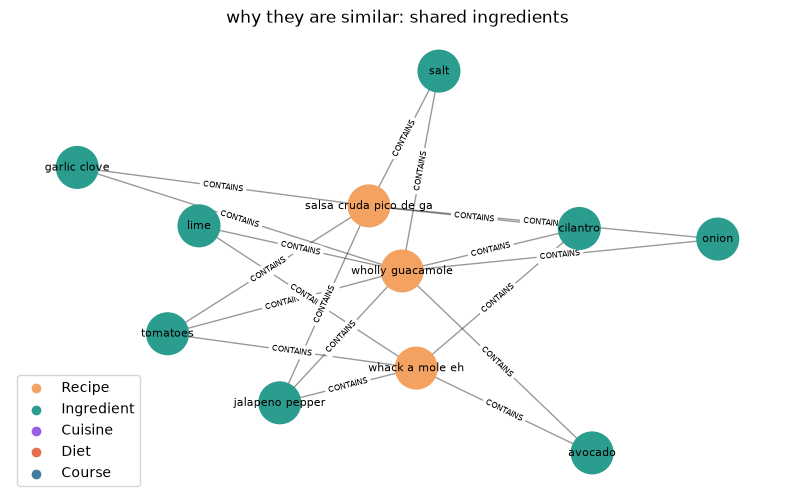

In [5]:
similar = api(f"/api/recipes/{RECIPE_ID}/similar", limit=3)
display(pd.DataFrame(similar["similar"])[["name", "score", "shared_ingredients"]])
edges = []
for item in similar["similar"][:2]:
    for ingredient in item["shared_ingredients"]:
        edges.append((similar["recipe_name"], "Recipe", ingredient, "Ingredient", "CONTAINS"))
        edges.append((item["name"], "Recipe", ingredient, "Ingredient", "CONTAINS"))
draw(edges, "why they are similar: shared ingredients", size=(10, 6))

Takeaways:
- the score is a Jaccard index weighted by how rare each ingredient is (IDF): avocado counts more than salt
- the explanation is a real path in the graph: recipe -> ingredient <- recipe

## 5. Recipe families (GDS Louvain)

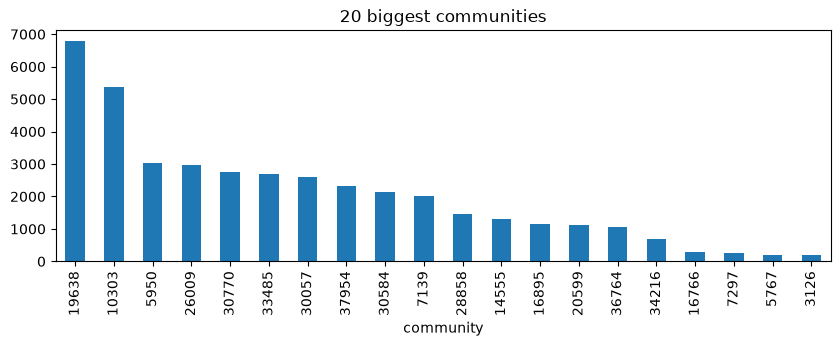

wholly guacamole -> community 30770 with 2763 recipes
characteristic ingredients: ['cilantro', 'salsa', 'chili powder', 'onion', 'sour cream', 'lime juice', 'black beans', 'cheddar cheese']


,id,name,reviews
0,89204,crock pot chicken with black beans cream cheese,987
1,28148,oven fried chicken chimichangas,638
2,33919,creamy burrito casserole,588
3,129926,simply sour cream chicken enchiladas,380
4,27520,poverty meal,323


In [6]:
sizes = pd.DataFrame(db.run_read(
    "MATCH (r:Recipe) WHERE r.community IS NOT NULL RETURN r.community AS community, count(*) AS recipes "
    "ORDER BY recipes DESC LIMIT 20"))
sizes.plot.bar(x="community", y="recipes", legend=False, title="20 biggest communities", figsize=(10, 3))
plt.show()
family = api(f"/api/recipes/{RECIPE_ID}/community", limit=5)
print(family["recipe_name"], "-> community", family["community"], "with", family["size"], "recipes")
print("characteristic ingredients:", family["characteristic_ingredients"])
pd.DataFrame(family["popular_recipes"])

Takeaways:
- 510 communities found from the similarity graph only, without the cuisine tags
- the guacamole family is Mexican / Tex-Mex cooking (cilantro, salsa, black beans, burritos)

## 6. Path between two recipes (pathfinding)

found: True | steps: 4


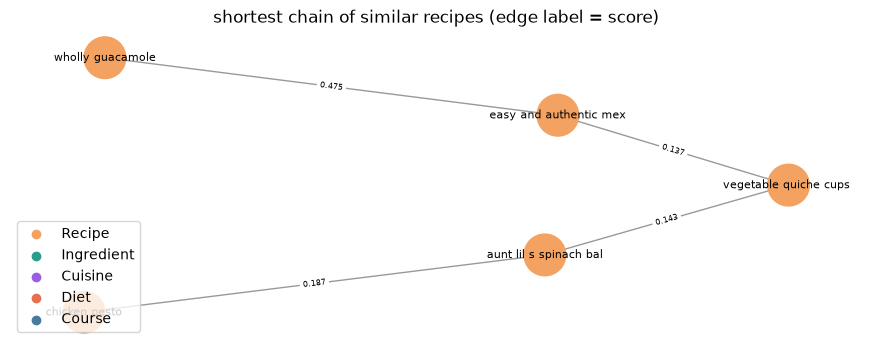

In [7]:
path = api("/api/recipes/path", **{"from": RECIPE_ID, "to": 21882})
print("found:", path["found"], "| steps:", path["length"])
names = [step["name"] for step in path["path"]]
draw([(a, "Recipe", b, "Recipe", f"{s}") for a, b, s in zip(names, names[1:], path["scores"])],
     "shortest chain of similar recipes (edge label = score)", size=(11, 4))

## 7. Why indexes matter (PROFILE)

In [8]:
from scripts.benchmark import total_db_hits

query = "MATCH (r:Recipe {id: $id}) RETURN r.name"
scan = "MATCH (r:Recipe) USING SCAN r:Recipe WHERE r.id = $id RETURN r.name"
pd.DataFrame([
    {"version": "with the unique constraint index", "db hits": total_db_hits(db.profile(query, {"id": RECIPE_ID}))},
    {"version": "forced to scan every recipe", "db hits": total_db_hits(db.profile(scan, {"id": RECIPE_ID}))},
])

,version,db hits
0,with the unique constraint index,3
1,forced to scan every recipe,82482


More measurements (indexes and query rewrites, before / after): docs/benchmarks.md, make benchmark.

## 8. Natural-language agent (Gemini + guardrails)

In [9]:
answer = httpx.post(API + "/api/ask", json={"question": "Which cuisine has the most vegan recipes?", "summarize": False},
                    timeout=120)
if answer.status_code == 200:
    body = answer.json()
    print("status:", body["status"], "| attempts:", body["attempts"])
    print("cypher:", body["cypher"])
    print("trace:", [step["step"] + ": " + step["detail"] for step in body["trace"]])
    display(pd.DataFrame(body["results"]))
else:
    print(answer.status_code, answer.json())  # 503: no Gemini key, or Gemini overloaded / out of free quota

status: answered | attempts: 1
cypher: MATCH (r:Recipe)-[:FITS_DIET]->(:Diet {name: 'vegan'}), (r)-[:HAS_CUISINE]->(sub:Cuisine)-[:PART_OF*0..4]->(c:Cuisine) RETURN c.name AS cuisine, count(DISTINCT r) AS vegan_recipes ORDER BY vegan_recipes DESC LIMIT 1
trace: ['generate #1: query written (self-reported confidence 1.00)', 'validate: all checks passed', 'execute: 1 rows returned by Neo4j']


,cuisine,vegan_recipes
0,north-american,483


In [10]:
for cypher in ["MATCH (n) DETACH DELETE n", "MATCH (r:Recipe) WHERE r.rating > 4 RETURN r.name"]:
    check = httpx.post(API + "/api/ask/check", json={"cypher": cypher}, timeout=30).json()
    failed = [c["detail"] for c in check["checks"] if not c["passed"]]
    print(f"{cypher}\n  allowed: {check['passed']} | {failed}\n")

MATCH (n) DETACH DELETE n
  allowed: False | ['write clauses are not allowed: DELETE, DETACH', 'the query must end with RETURN']

MATCH (r:Recipe) WHERE r.rating > 4 RETURN r.name
  allowed: False | ['not in the graph schema: property .rating on r']



Takeaways:
- the answer keeps the verified rows (from Neo4j) apart from the AI text, and shows every step
- the guardrails refuse write queries and names that are not in the schema (rating is on REVIEWED, not on Recipe), before anything reaches the database
- details: docs/agent.md

## 9. ML: is this recipe vegetarian?

In [11]:
from pathlib import Path

print("\n".join(line for line in Path("docs/ml.md").read_text(encoding="utf-8").splitlines() if line.startswith("|")))

| model | metrics |
|---|---|
| baseline (random, same class balance) | accuracy 0.722, precision 0.176, recall 0.17, f1 0.173, roc_auc 0.503 |
| logistic regression on FastRP embeddings | accuracy 0.664, precision 0.286, recall 0.64, f1 0.395, roc_auc 0.704 |


Takeaways:
- FastRP embeddings + logistic regression: ROC AUC 0.70 against 0.50 for a random baseline (make ml)
- the tag is missing on many vegetarian recipes, so the model can also suggest tags (docs/ml.md)

In [12]:
db.close()